## CSCI-e89: Deep Learning, Fall 2026

<img style="float: left; padding-right: 50px; width: 50px" src="images/ExtensionFlag.jpg" alt="ExtensionFlag.jpg"/>

* **Harvard University Extension School - Lab 09- Speech Analysis**
* **Joan Imrich October 31, 2026**

<hr style="height:2pt">

# Speech Commands: MFCC → CNN → Transformer comparison
CNN code and a trainable transformer comparison
Internet is needed for installation and the dataset download (several GB). Models are trained from scratch; no accuracy is claimed before execution. CPU works; GPU is faster. Default subsets keep training small, not the download.

We use human recordings directly: **Piper/NeuTTS are speech generators, not required for this classification exercise.** This notebook focuses on a simple supervised pipeline.

## 1. Install and configure
Recommended: fresh Python 3.10–3.12 environment. This example pins a matching torch/torchaudio pair. Skip the installation if you already have a compatible installation. Restart the kernel after installation if these packages were already imported. Audio is decoded with SoundFile.

In [1]:
#%pip install -q torch==2.5.1 torchaudio==2.5.1 numpy matplotlib scikit-learn soundfile pandas
#%pip install scikit-learn

In [2]:
import random, time, math
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from torch import nn
import torch.nn.functional as F
import torchaudio
from torchaudio.datasets import SPEECHCOMMANDS
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from IPython.display import Audio, display
import time as timer

SEED = 42
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SR, N_SAMPLES = 16000, 16000
BATCH_SIZE, EPOCHS = 64, 12
TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 100, 30, 50
ROOT = Path('data'); ROOT.mkdir(exist_ok=True)
print(torch.__version__, torchaudio.__version__, DEVICE)
# Seeds improve repeatability, but do not guarantee identical GPU results.

2.6.0+cpu 2.6.0+cpu cpu


## 2. Official data splits
`SPEECHCOMMANDS` supports training, validation and testing subsets directly. We retain those boundaries and optionally sample within each class. Metadata gives labels without decoding every recording.

This is 35-class closed-set recognition: silence and unknown words are not separate output classes. A deployed detector needs an explicit strategy for them.

In [3]:
datasets = {
    split: SPEECHCOMMANDS(str(ROOT), download=True, subset=split)
    for split in ['training', 'validation', 'testing']
}
labels = sorted({datasets['training'].get_metadata(i)[2]
                 for i in range(len(datasets['training']))})
label_to_id = {name: i for i, name in enumerate(labels)}
assert len(labels) == 35
print(labels)
print({split: len(ds) for split, ds in datasets.items()})

def audio_path(ds, index):
    # Metadata paths are relative to torchaudio's archive root.
    return Path(ds._archive) / ds.get_metadata(index)[0]

def read_audio(path):
    array, sr = sf.read(str(path), dtype='float32', always_2d=True)
    return torch.from_numpy(array.T.copy()), sr

def prepare(wave, sr):
    if wave.ndim == 1:
        wave = wave.unsqueeze(0)
    wave = wave.float().mean(0, keepdim=True)
    if sr != SR:
        wave = torchaudio.functional.resample(wave, sr, SR)
    wave = wave[..., :N_SAMPLES]
    return F.pad(wave, (0, N_SAMPLES-wave.shape[-1]))

wave, sr = read_audio(audio_path(datasets['training'], 0))
x = prepare(wave, sr)[0]


# Find one training recording for each spoken word.
target_words = ["bird", "cat", "dog"]
train_set = datasets["training"]
sample_indices = {}

for i in range(len(train_set)):
    word = train_set.get_metadata(i)[2]

    if word in target_words and word not in sample_indices:
        sample_indices[word] = i

    if len(sample_indices) == len(target_words):
        break

# Store each sample for playback and later analysis.
samples = {}

for word in target_words:
    if word not in sample_indices:
        print(f"No recording found for {word!r}.")
        continue

    index = sample_indices[word]
    wave, sr = read_audio(audio_path(train_set, index))
    x = prepare(wave, sr)[0]

    samples[word] = {
        "index": index,
        "wave": wave,
        "sr": sr,
        "x": x,
    }

    print(
        f"\nWord: {word} | "
        f"Sample rate: {sr} Hz | "
        f"Original duration: {wave.shape[-1] / sr:.3f} seconds"
    )

    display(Audio(wave.numpy(), rate=sr))


# print('Word:', datasets['training'].get_metadata(0)[2])
# display(Audio(wave.numpy(), rate=sr))

['backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five', 'follow', 'forward', 'four', 'go', 'happy', 'house', 'learn', 'left', 'marvin', 'nine', 'no', 'off', 'on', 'one', 'right', 'seven', 'sheila', 'six', 'stop', 'three', 'tree', 'two', 'up', 'visual', 'wow', 'yes', 'zero']
{'training': 84843, 'validation': 9981, 'testing': 11005}

Word: bird | Sample rate: 16000 Hz | Original duration: 0.597 seconds



Word: cat | Sample rate: 16000 Hz | Original duration: 1.000 seconds



Word: dog | Sample rate: 16000 Hz | Original duration: 1.000 seconds


## 3. Waveforms, FFT and frequency versus amplitude
A digital mono signal is a vector of sampled amplitudes:
$$x=[x[0],x[1],\ldots,x[N-1]].$$
At 16 kHz, one second contains 16,000 samples. Values describe relative digital amplitude, not calibrated sound pressure. Mean-square amplitude averages $x[n]^2$; RMS is its square root. Loudness also depends on hearing and spectral content.

The DFT represents the signal using complex sinusoidal coefficients:
$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}.$$
FFT is an efficient algorithm for the DFT. Coefficients contain magnitude and phase; bin frequency is $kf_s/N$. At 16 kHz the Nyquist frequency is 8 kHz.

Changing amplitude changes spectral magnitude; changing frequency moves spectral energy between bins. Plot $20\log_{10}|X|$ for amplitude or $10\log_{10}P$ for power. These are relative levels unless calibrated.

bird: inverse FFT maximum error = 8.941e-08
cat: inverse FFT maximum error = 2.235e-08
dog: inverse FFT maximum error = 1.788e-07


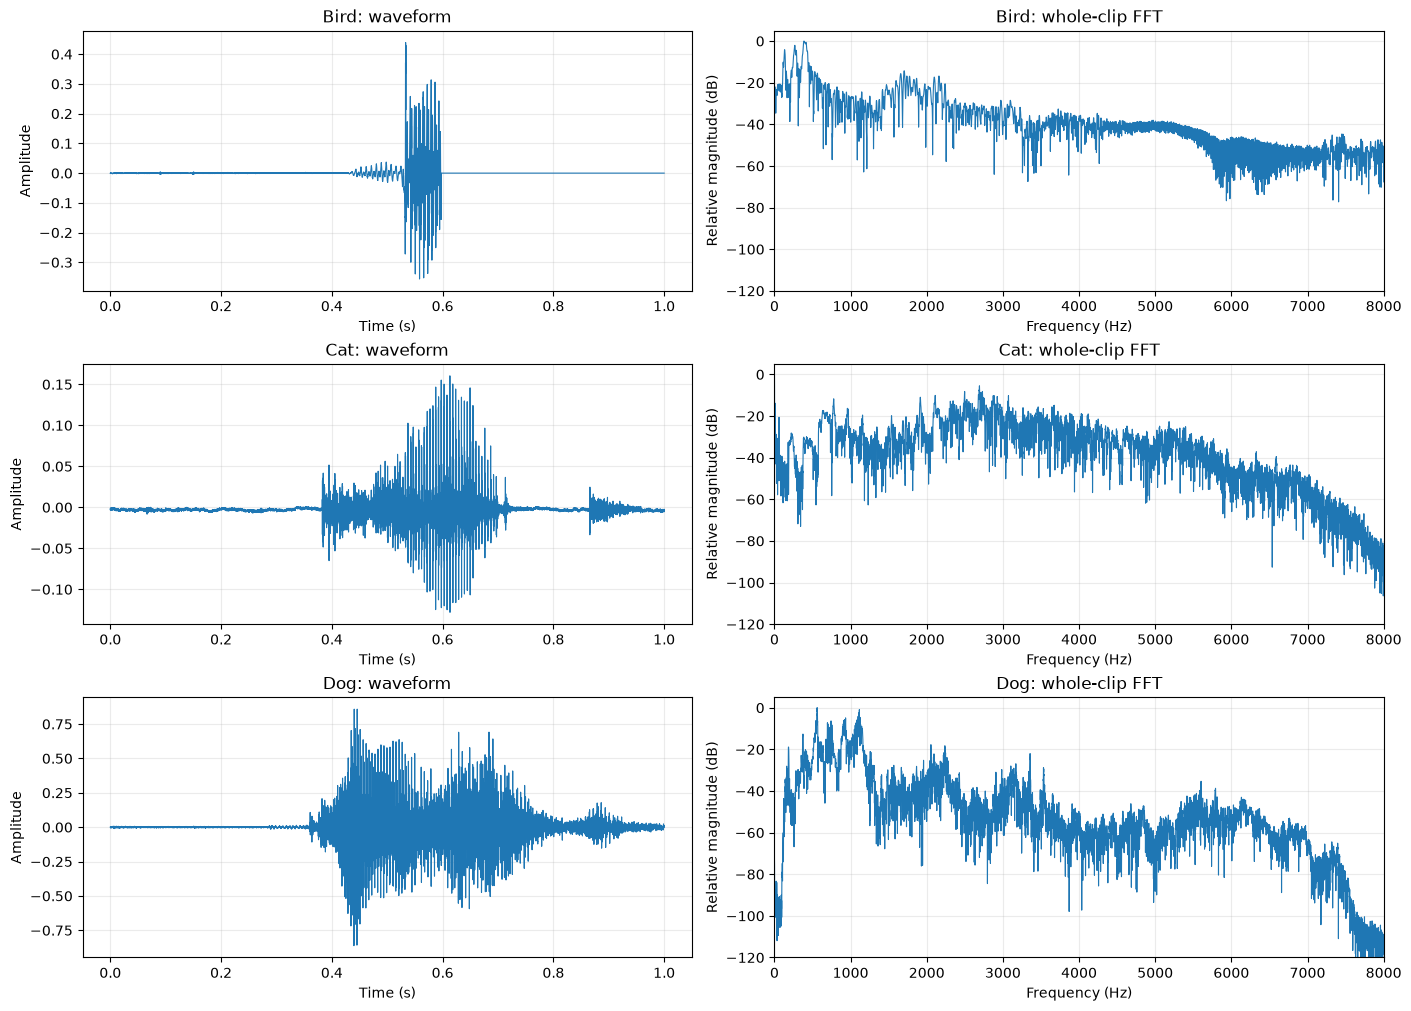

In [4]:
target_words = ["bird", "cat", "dog"]

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), constrained_layout=True
)

for row, word in enumerate(target_words):
    # Prepared audio vector saved in the previous cell.
    x = samples[word]["x"].detach().cpu()
    n = x.numel()

    # Waveform.

    # Waveform.
    time_axis = np.arange(n) / SR
    axes[row, 0].plot(time_axis, x.numpy(), linewidth=0.8)

    axes[row, 0].set(
        xlabel="Time (s)",
        ylabel="Amplitude",
        title=f"{word.capitalize()}: waveform",
    )
    axes[row, 0].grid(alpha=0.25)

    # Windowed whole-clip FFT.
    window = torch.hann_window(n, dtype=x.dtype)
    freq = torch.fft.rfftfreq(n, d=1 / SR)
    spec = torch.fft.rfft(x * window).abs()

    db = 20 * torch.log10(
        (spec / spec.max().clamp_min(1e-12)).clamp_min(1e-6)
    )

    axes[row, 1].plot(freq.numpy(), db.numpy(), linewidth=0.8)
    axes[row, 1].set(
        xlabel="Frequency (Hz)",
        ylabel="Relative magnitude (dB)",
        title=f"{word.capitalize()}: whole-clip FFT",
        xlim=(0, SR / 2),
        ylim=(-120, 5),
    )
    axes[row, 1].grid(alpha=0.25)

    # Inverse FFT check on the original, unwindowed vector.
    recovered = torch.fft.irfft(torch.fft.rfft(x), n=n)
    error = (x - recovered).abs().max().item()

    print(f"{word}: inverse FFT maximum error = {error:.3e}")

plt.show()

bird: log-mel shape = (1, 40, 97) | MFCC shape = (1, 13, 97)
cat: log-mel shape = (1, 40, 97) | MFCC shape = (1, 13, 97)
dog: log-mel shape = (1, 40, 97) | MFCC shape = (1, 13, 97)


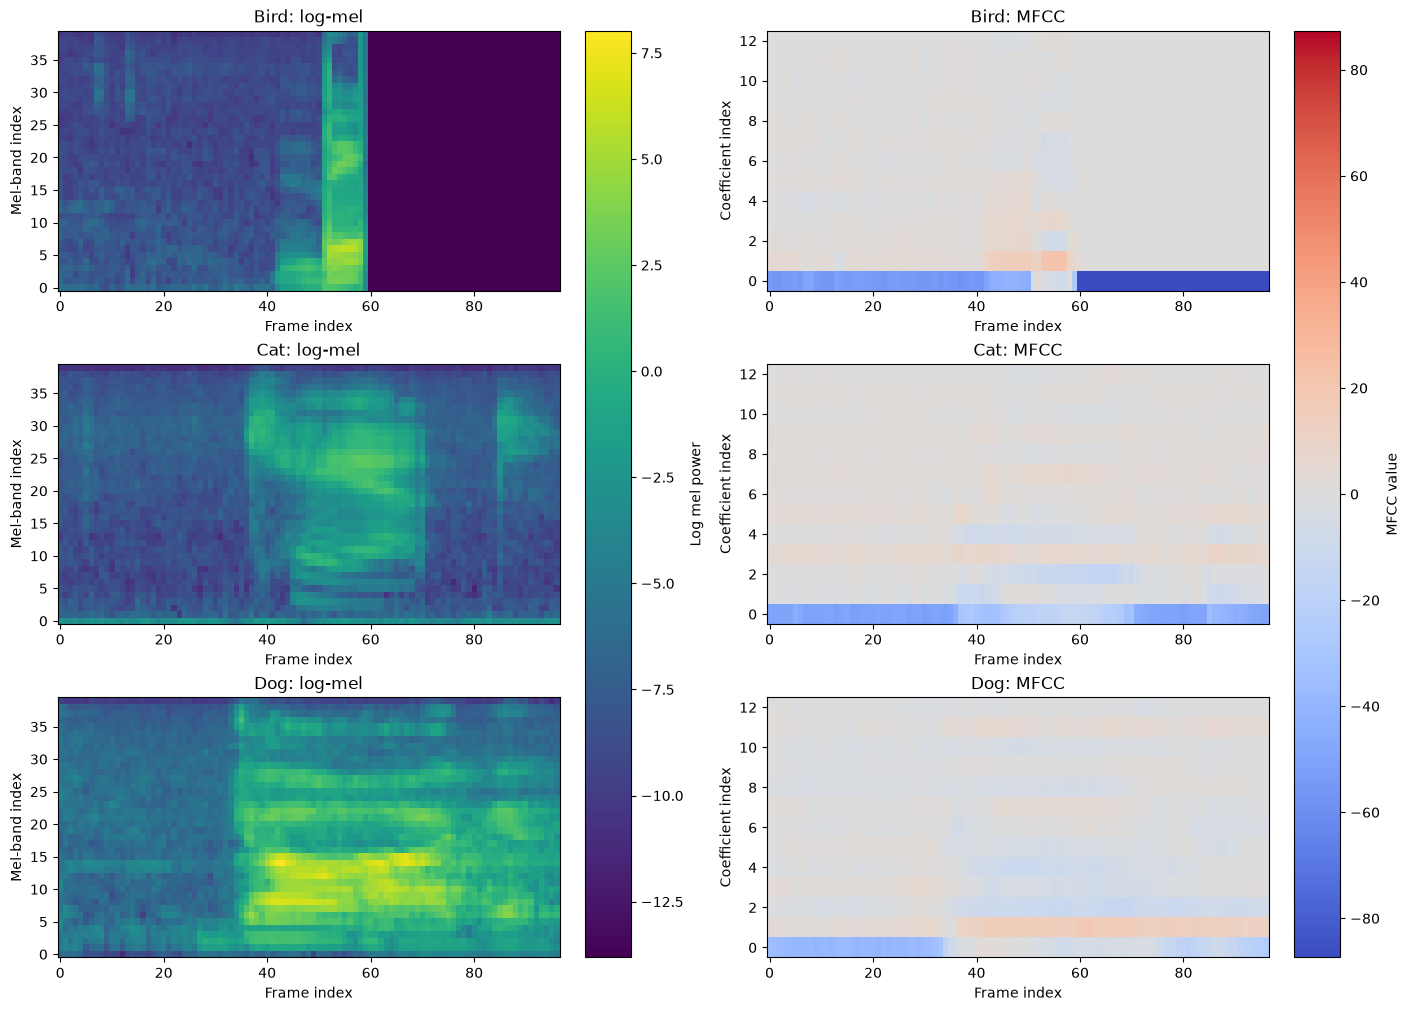

Shape order: [channel, feature, frame]


In [5]:
MEL = dict(
    n_fft=512,
    win_length=400,
    hop_length=160,
    n_mels=40,
    f_min=20.,
    f_max=SR / 2,
    power=2.,
    center=False,
)

mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=SR,
    n_mfcc=13,
    log_mels=True,
    melkwargs=MEL,
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SR,
    **MEL,
)

target_words = ["bird", "cat", "dog"]
sample_features = {}

# Compute features for all three samples.
with torch.no_grad():
    for word in target_words:
        x = samples[word]["x"].detach().cpu()
        wave = x.unsqueeze(0)  # [channel, samples]

        sample_features[word] = {
            "mfcc": mfcc_transform(wave),
            "logmel": torch.log(mel_transform(wave) + 1e-6),
        }

# Use shared color scales within each feature type.
mel_min = min(
    features["logmel"].min().item()
    for features in sample_features.values()
)
mel_max = max(
    features["logmel"].max().item()
    for features in sample_features.values()
)
mfcc_limit = max(
    features["mfcc"].abs().max().item()
    for features in sample_features.values()
)

fig, axes = plt.subplots(
    3, 2, figsize=(14, 10), constrained_layout=True
)

for row, word in enumerate(target_words):
    logmel = sample_features[word]["logmel"]
    mfcc = sample_features[word]["mfcc"]

    mel_image = axes[row, 0].imshow(
        logmel[0].numpy(),
        origin="lower",
        aspect="auto",
        vmin=mel_min,
        vmax=mel_max,
    )
    axes[row, 0].set(
        title=f"{word.capitalize()}: log-mel",
        xlabel="Frame index",
        ylabel="Mel-band index",
    )

    mfcc_image = axes[row, 1].imshow(
        mfcc[0].numpy(),
        origin="lower",
        aspect="auto",
        cmap="coolwarm",
        vmin=-mfcc_limit,
        vmax=mfcc_limit,
    )
    axes[row, 1].set(
        title=f"{word.capitalize()}: MFCC",
        xlabel="Frame index",
        ylabel="Coefficient index",
    )

    print(
        f"{word}: "
        f"log-mel shape = {tuple(logmel.shape)} | "
        f"MFCC shape = {tuple(mfcc.shape)}"
    )

fig.colorbar(
    mel_image,
    ax=axes[:, 0].tolist(),
    label="Log mel power",
)
fig.colorbar(
    mfcc_image,
    ax=axes[:, 1].tolist(),
    label="MFCC value",
)

plt.show()

print("Shape order: [channel, feature, frame]")

## 4. MFCC features
Pipeline: overlapping frames → Hann window → FFT → power → mel filters → logarithm → DCT → 13 coefficients.

- Window: 400 samples (25 ms); hop: 160 samples (10 ms).
- FFT: 512 points; 40 mel filters; `center=False`.
- Mel spacing allocates finer resolution to lower frequencies.
- Zero-padding to 512 points makes frequency sampling denser; it does not increase the resolving power of the 400-sample window.
- Logarithms compress dynamic range. For positive gain $a$:
$$\log(a^2P)=2\log|a|+\log P.$$
- The DCT summarizes log-mel spectral shape. We retain only 13 coefficients.

A logarithm does not return frequency features to time. Inverse FFT needs the complex spectrum, including phase. MFCCs discard phase, combine bins and discard DCT coefficients, so they are lossy. MFCC coefficient indices are not frequency-bin indices.

We explicitly select `log_mels=True`, instead of torchaudio's default dB-scaled input to the DCT.

bird: MFCC [channel, coefficient, frame] = (1, 13, 97)
cat: MFCC [channel, coefficient, frame] = (1, 13, 97)
dog: MFCC [channel, coefficient, frame] = (1, 13, 97)


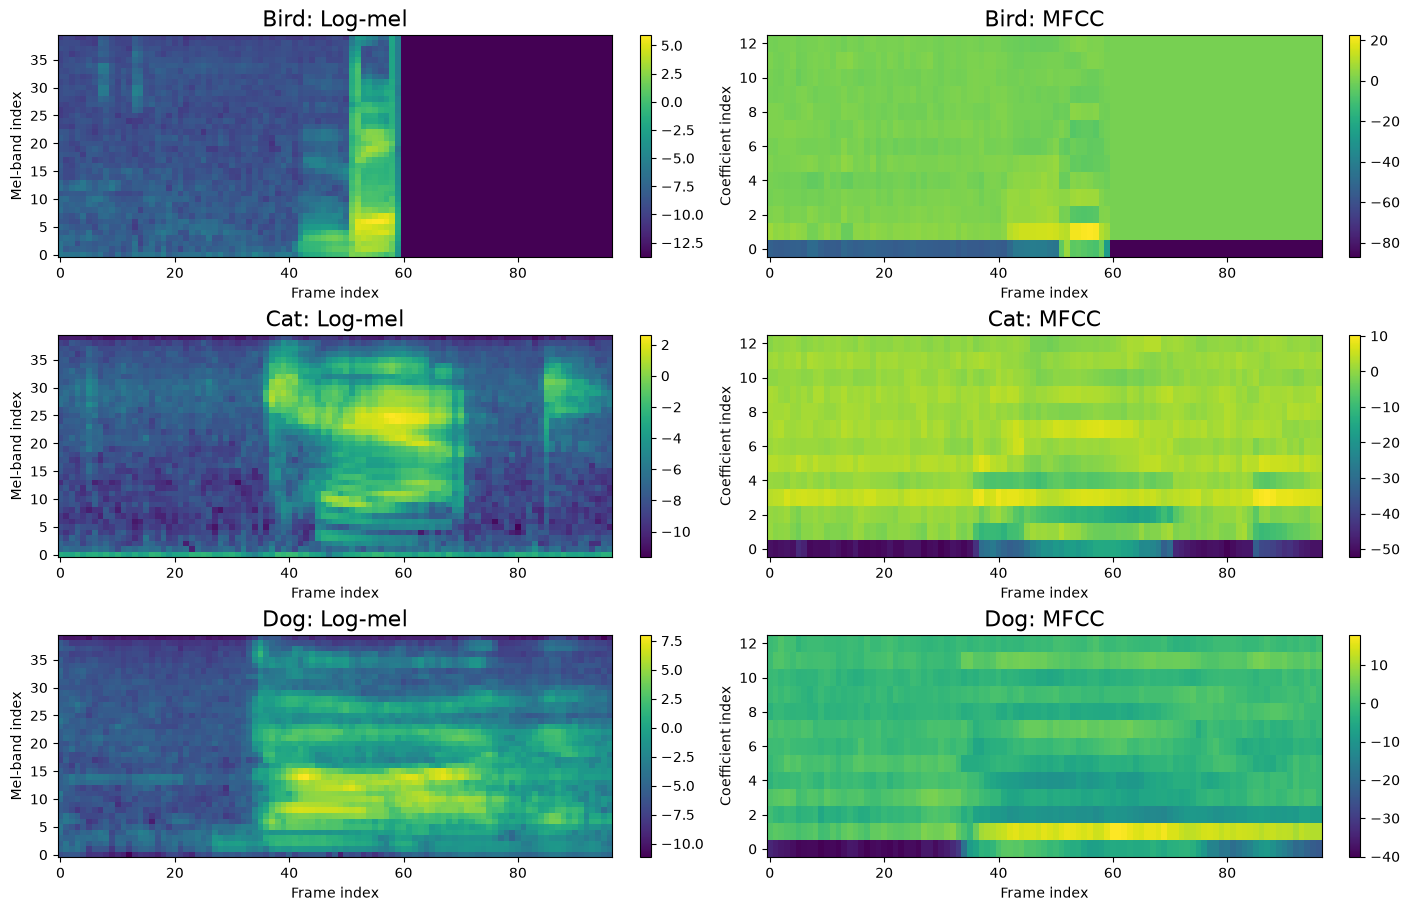

In [6]:
MEL = dict(
    n_fft=512,
    win_length=400,
    hop_length=160,
    n_mels=40,
    f_min=20.,
    f_max=SR / 2,
    power=2.,
    center=False,
)

mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=SR,
    n_mfcc=13,
    log_mels=True,
    melkwargs=MEL,
)

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SR,
    **MEL,
)

target_words = ["bird", "cat", "dog"]

fig, axes = plt.subplots(
    3, 2, figsize=(14, 9), constrained_layout=True
)

for row, word in enumerate(target_words):
    x = samples[word]["x"].detach().cpu()

    with torch.no_grad():
        mfcc = mfcc_transform(x.unsqueeze(0))
        logmel = torch.log(
            mel_transform(x.unsqueeze(0)) + 1e-6
        )

    for ax, feature, title, ylabel in zip(
        axes[row],
        [logmel[0], mfcc[0]],
        ["Log-mel", "MFCC"],
        ["Mel-band index", "Coefficient index"],
    ):
        image = ax.imshow(
            feature.numpy(),
            origin="lower",
            aspect="auto",
        )
        ax.set_title(f"{word.capitalize()}: {title}", fontsize=16)
        ax.set_xlabel("Frame index")
        ax.set_ylabel(ylabel)
        fig.colorbar(image, ax=ax)

    print(
        f"{word}: MFCC [channel, coefficient, frame] = "
        f"{tuple(mfcc.shape)}"
    )

plt.show()

## 5. Cache features and normalize without leakage
Select a reproducible random subset per word. Set limits to `None` for complete splits; memory use will increase.

Normalize each MFCC coefficient using only training examples and frames. Apply the same statistics to validation, testing and inference. Cache features once so both architectures receive identical inputs.

In [7]:
def cache(ds, limit, seed):
    groups = defaultdict(list)
    for i in range(len(ds)):
        groups[ds.get_metadata(i)[2]].append(i)
    rng = random.Random(seed)
    selected = []
    for word in labels:
        indices = groups[word].copy()
        rng.shuffle(indices)
        selected.extend(indices if limit is None else indices[:limit])
    features, targets = [], []
    with torch.no_grad():
        for start in range(0, len(selected), 128):
            batch = selected[start:start+128]
            waves = [prepare(*read_audio(audio_path(ds, i))) for i in batch]
            features.append(mfcc_transform(torch.stack(waves)))
            targets.extend(label_to_id[ds.get_metadata(i)[2]] for i in batch)
    return torch.cat(features), torch.tensor(targets)

X_train, y_train = cache(datasets['training'], TRAIN_PER_CLASS, SEED)
X_val, y_val = cache(datasets['validation'], VAL_PER_CLASS, SEED+1)
X_test, y_test = cache(datasets['testing'], TEST_PER_CLASS, SEED+2)
mean = X_train.mean(dim=(0, 3), keepdim=True)
std = X_train.std(dim=(0, 3), keepdim=True).clamp_min(1e-5)
X_train, X_val, X_test = [(v-mean)/std for v in [X_train, X_val, X_test]]
train_data = TensorDataset(X_train, y_train)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)
print('Train / validation / test:', X_train.shape, X_val.shape, X_test.shape)

Train / validation / test: torch.Size([3500, 1, 13, 97]) torch.Size([1050, 1, 13, 97]) torch.Size([1750, 1, 13, 97])


## 6. Complete CNN code
The input is `[B, 1, 13, 97]` for the configured one-second clips.

| Layer | Output shape | Purpose |
|---|---|---|
| Conv 3×3, padding 1 | B × 16 × 13 × 97 | Learn local patterns |
| ReLU | unchanged | Nonlinear activation |
| MaxPool 2×2 | B × 16 × 6 × 48 | Reduce feature/time resolution |
| Conv 3×3, padding 1 | B × 32 × 6 × 48 | Combine local patterns |
| ReLU | unchanged | Nonlinearity |
| Global average pooling | B × 32 × 1 × 1 | Summarize each learned channel |
| Flatten, dropout | B × 32 | Regularization |
| Linear | B × 35 | Unnormalized class logits |

`forward` specifies the data flow. Convolution weights and the final linear layer are learned. Pooling has no learned weights. Dropout is active only during training. Global pooling is compact but removes much precise temporal arrangement.

This is a teaching baseline: neighboring MFCC coefficients do not correspond to neighboring frequency bands. A log-mel CNN is a useful additional comparison.

In [8]:
class SmallMFCCCNN(nn.Module):
    def __init__(self, n_classes=35):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(32, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.head(x)

cnn = SmallMFCCCNN(len(labels))
print(cnn)
print('Parameters:', sum(p.numel() for p in cnn.parameters()))
with torch.no_grad():
    print('Logit shape:', cnn(X_train[:2]).shape)

SmallMFCCCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.2, inplace=False)
    (2): Linear(in_features=32, out_features=35, bias=True)
  )
)
Parameters: 5955
Logit shape: torch.Size([2, 35])


## 7. Shared training code
Cross-entropy consumes logits directly; do not add softmax before this loss. Backpropagation computes gradients, and AdamW updates the weights. `eval()` disables dropout; `no_grad()` avoids gradient tracking during evaluation.

For each model, choose the checkpoint with the lowest validation loss. Both use identical splits, preprocessing, epochs, batch size, optimizer settings and seeded shuffle. Equal settings are a baseline comparison, not proof that either model is optimally tuned.

In [9]:
import time as timer

import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader


def epoch_pass(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    loss_sum = 0.0
    correct = 0
    count = 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)
            loss = F.cross_entropy(logits, yb)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = len(yb)
            loss_sum += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += batch_size

    if count == 0:
        raise ValueError("The data loader contains no samples.")

    return loss_sum / count, correct / count


def fit(model, name):
    if EPOCHS < 1:
        raise ValueError("EPOCHS must be at least 1.")

    device = torch.device(DEVICE)
    model = model.to(device)

    loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )

    best_loss = float("inf")
    best_state = None
    history = []

    # Start timing immediately before training.
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    start = timer.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = epoch_pass(
            model, loader, optimizer
        )
        val_loss, val_accuracy = epoch_pass(
            model, val_loader
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} {epoch:02d}: "
            f"train {train_accuracy:.3f}, "
            f"val {val_accuracy:.3f}, "
            f"val loss {val_loss:.4f}"
        )

    # Finish timing after all training and validation passes.
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    elapsed = timer.perf_counter() - start

    if best_state is None:
        raise RuntimeError(
            "No best checkpoint was recorded. "
            "Check validation losses for NaN or infinity."
        )

    model.load_state_dict(best_state)
    model.eval()

    return model, pd.DataFrame(history), elapsed


seed_all()

cnn = SmallMFCCCNN(len(labels))
cnn, cnn_history, cnn_seconds = fit(cnn, "CNN")

print(f"\nCNN training time: {cnn_seconds:.2f} seconds")

CNN 01: train 0.026, val 0.043, val loss 3.5572
CNN 02: train 0.029, val 0.044, val loss 3.5544
CNN 03: train 0.033, val 0.039, val loss 3.5495
CNN 04: train 0.040, val 0.043, val loss 3.5435
CNN 05: train 0.045, val 0.052, val loss 3.5354
CNN 06: train 0.053, val 0.042, val loss 3.5225
CNN 07: train 0.053, val 0.062, val loss 3.5048
CNN 08: train 0.073, val 0.079, val loss 3.4695
CNN 09: train 0.069, val 0.082, val loss 3.4369
CNN 10: train 0.078, val 0.112, val loss 3.3925
CNN 11: train 0.092, val 0.109, val loss 3.3502
CNN 12: train 0.097, val 0.131, val loss 3.2931

CNN training time: 12.31 seconds


## 8. New section: transformer architecture and complete code
Treat each time frame as a token containing 13 MFCC values. Project it to 64 dimensions, add learned positional embeddings, then apply two transformer encoder blocks with four attention heads each. Mean-pool the sequence and classify it.

With `batch_first=True`, attention receives `[B, T, 64]`, not the CNN layout. Each encoder contains multi-head self-attention, a feed-forward network, residual connections and layer normalization.

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\mathsf{T}}{\sqrt{d_k}}\right)V.$$
Queries and keys determine frame-to-frame weights; values supply the information combined by those weights. Position embeddings supply order information.

All clips are fixed length after padding/cropping. We intentionally treat padded silence as part of the input for both models, rather than claiming to mask it. For variable-length modeling, preserve valid lengths and use padding masks and masked pooling.

The two encoder layers below are constructed independently rather than relying on cloned layers with identical initial values.

In [12]:
class SmallMFCCTransformer(nn.Module):
    def __init__(
        self,
        n_classes=35,
        max_frames=128,
        d_model=64,
        nhead=4,
        num_layers=2,
    ):
        super().__init__()

        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead.")

        self.projection = nn.Linear(13, d_model)

        self.position = nn.Parameter(
            torch.zeros(1, max_frames, d_model)
        )
        nn.init.normal_(self.position, std=0.02)

        self.blocks = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=128,
                dropout=0.1,
                activation="gelu",
                batch_first=True,
            )
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 1 or x.shape[2] != 13:
            raise ValueError(
                "Expected input [batch, 1, 13, frames], "
                f"got {tuple(x.shape)}."
            )

        # [B, 1, 13, T] -> [B, T, 13]
        x = x.squeeze(1).transpose(1, 2)

        frames = x.shape[1]
        if frames > self.position.shape[1]:
            raise ValueError(
                f"Input has {frames} frames, but max_frames="
                f"{self.position.shape[1]}. "
                "Recreate the model with a larger max_frames."
            )

        x = self.projection(x) + self.position[:, :frames]

        for block in self.blocks:
            x = block(x)

        x = self.norm(x).mean(dim=1)
        return self.head(x)


def epoch_pass(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    device = next(model.parameters()).device
    loss_sum = 0.0
    correct = 0
    count = 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)
            loss = F.cross_entropy(logits, yb)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = yb.shape[0]
            loss_sum += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += batch_size

    if count == 0:
        raise ValueError("The data loader contains no samples.")

    return loss_sum / count, correct / count


def fit(model, name):
    if EPOCHS < 1:
        raise ValueError("EPOCHS must be at least 1.")

    device = torch.device(DEVICE)
    model = model.to(device)

    loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )

    best_loss = float("inf")
    best_state = None
    history = []

    if device.type == "cuda":
        torch.cuda.synchronize(device)

    start = timer.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = epoch_pass(
            model, loader, optimizer
        )
        val_loss, val_accuracy = epoch_pass(
            model, val_loader
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy,
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} {epoch:02d}: "
            f"train {train_accuracy:.3f}, "
            f"val {val_accuracy:.3f}, "
            f"val loss {val_loss:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize(device)

    elapsed = timer.perf_counter() - start

    if best_state is None:
        raise RuntimeError(
            "No valid best checkpoint was recorded. "
            "Check validation losses for NaN or infinity."
        )

    model.load_state_dict(best_state)
    model.eval()

    # Always return three values, on CPU or GPU.
    return model, pd.DataFrame(history), elapsed


# Initialize and inspect the model.
seed_all()

transformer = SmallMFCCTransformer(
    n_classes=len(labels),
    max_frames=max(128, int(X_train.shape[-1])),
).to(DEVICE)

print(transformer)
print(
    "Parameters:",
    sum(p.numel() for p in transformer.parameters()),
)

transformer.eval()
with torch.no_grad():
    example = X_train[:2].to(DEVICE)
    print("Input shape:", tuple(example.shape))
    print("Logit shape:", tuple(transformer(example).shape))

# Train and restore the best validation-loss checkpoint.
transformer, transformer_history, transformer_seconds = fit(
    transformer,
    "Transformer",
)

print(f"\nTransformer training time: {transformer_seconds:.2f} seconds")

SmallMFCCTransformer(
  (projection): Linear(in_features=13, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (linear1): Linear(in_features=64, out_features=128, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=128, out_features=64, bias=True)
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (head): Linear(in_features=64, out_features=35, bias=True)
)
Parameters: 78435
Input shape: (2, 1, 13, 97)
Logit shape: (2, 35)
Transformer 01: train 0.118, val 0.167, val loss 2.8389
Transformer 02: train 0.251,

## 9. Compare held-out results
Only after both models have been selected using validation loss do we evaluate test performance. Report parameter count, measured training wall time and accuracy. Time includes validation and depends on hardware; it is not an inference latency benchmark.

Do not repeatedly tune against test results. One seed and a small subset cannot establish a universally better architecture. A stronger study repeats seeds and tunes each model using validation only.

,model,parameters,training_seconds,selected_validation_accuracy,test_accuracy
0,CNN,5955,12.314661,0.131429,0.117143
1,Transformer,78435,64.739928,0.693333,0.686857


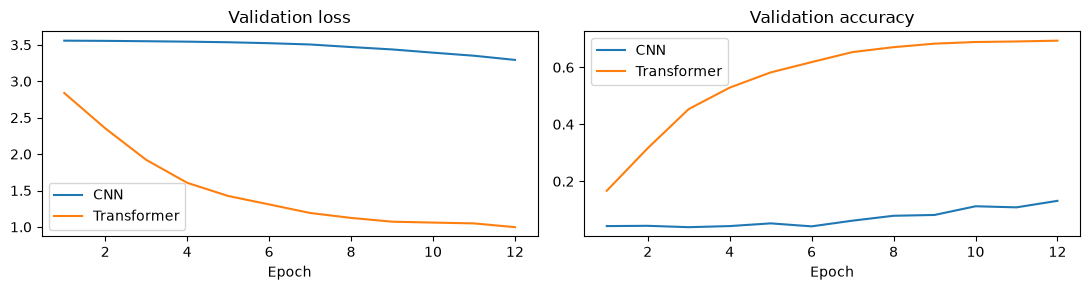

CNN
              precision    recall  f1-score   support

    backward      0.021     0.020     0.021        50
         bed      0.000     0.000     0.000        50
        bird      0.750     0.060     0.111        50
         cat      0.190     0.080     0.113        50
         dog      0.100     0.120     0.109        50
        down      0.056     0.040     0.047        50
       eight      0.167     0.060     0.088        50
        five      0.000     0.000     0.000        50
      follow      0.079     0.060     0.068        50
     forward      0.091     0.680     0.160        50
        four      0.036     0.040     0.038        50
          go      0.000     0.000     0.000        50
       happy      0.000     0.000     0.000        50
       house      0.186     0.160     0.172        50
       learn      0.011     0.020     0.014        50
        left      0.000     0.000     0.000        50
      marvin      0.155     0.180     0.167        50
        nine      0.167

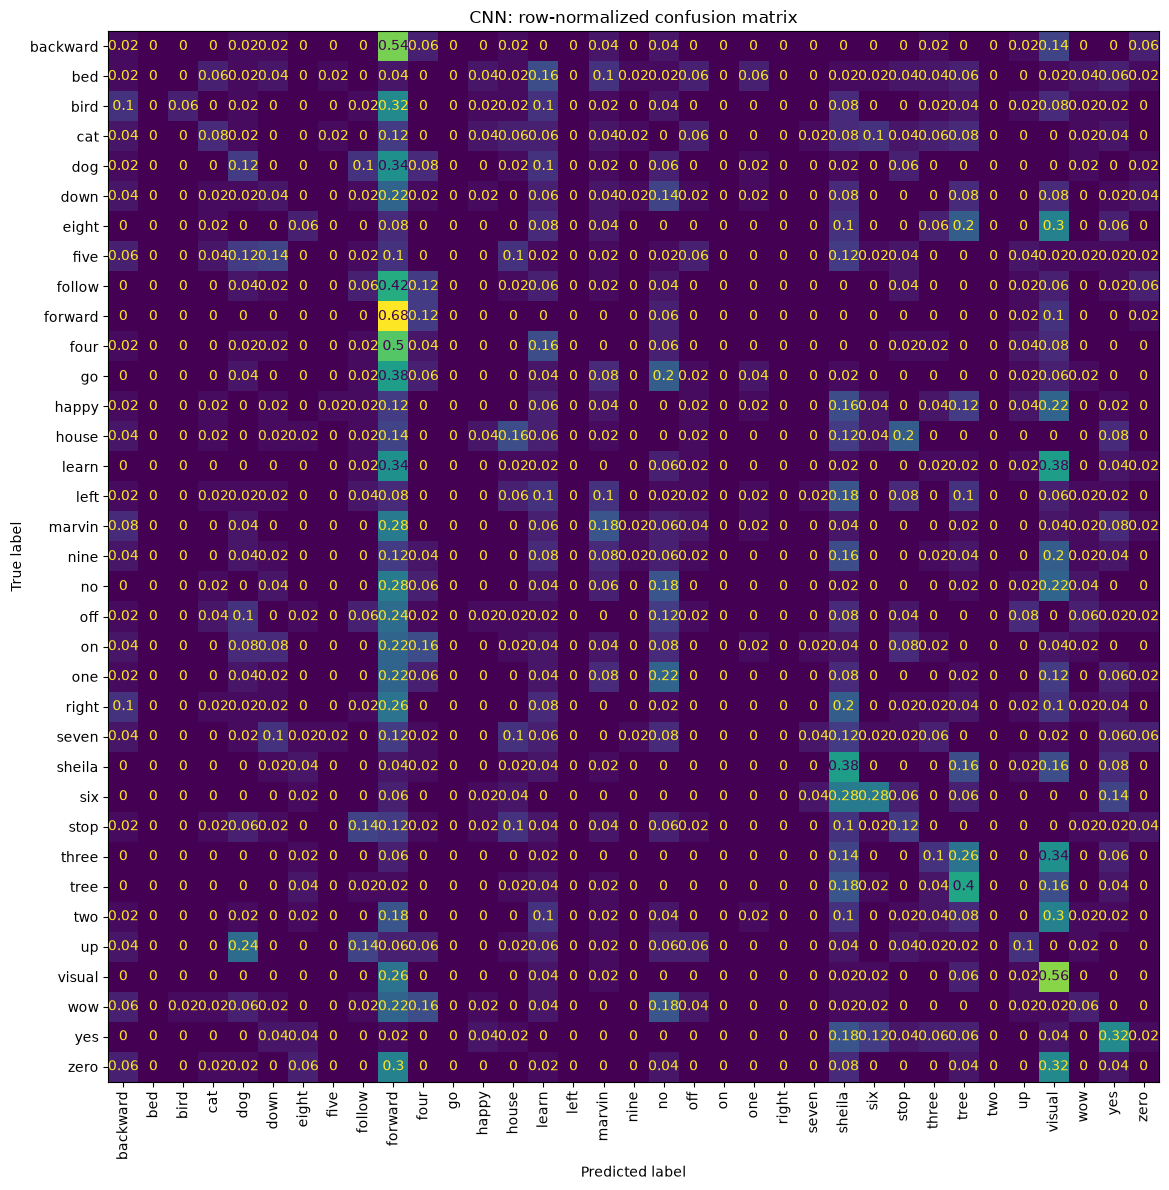

Transformer
              precision    recall  f1-score   support

    backward      0.585     0.620     0.602        50
         bed      0.462     0.860     0.601        50
        bird      0.618     0.840     0.712        50
         cat      0.881     0.740     0.804        50
         dog      0.733     0.440     0.550        50
        down      0.705     0.620     0.660        50
       eight      0.720     0.720     0.720        50
        five      0.744     0.640     0.688        50
      follow      0.500     0.560     0.528        50
     forward      0.593     0.700     0.642        50
        four      0.659     0.540     0.593        50
          go      0.511     0.480     0.495        50
       happy      0.698     0.740     0.718        50
       house      0.857     0.720     0.783        50
       learn      0.617     0.580     0.598        50
        left      0.679     0.720     0.699        50
      marvin      0.941     0.640     0.762        50
        nine   

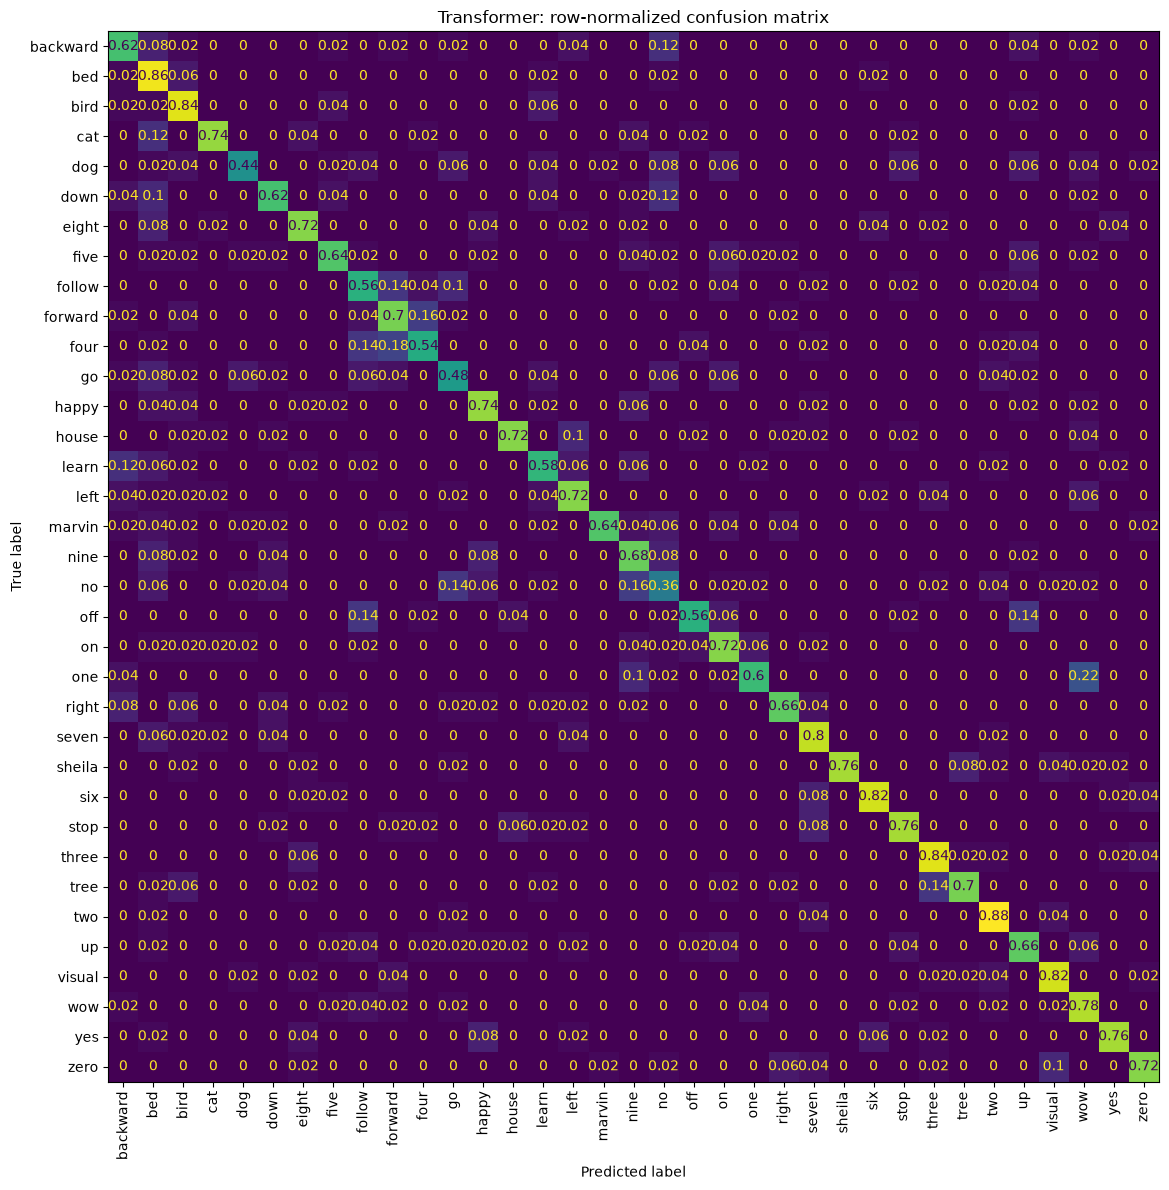

In [13]:
@torch.inference_mode()
def evaluate(model):
    truth, prediction = [], []
    model.eval()
    for xb, yb in test_loader:
        prediction.extend(model(xb.to(DEVICE)).argmax(1).cpu().tolist())
        truth.extend(yb.tolist())
    return np.array(truth), np.array(prediction)

models = {'CNN': cnn, 'Transformer': transformer}
histories = {'CNN': cnn_history, 'Transformer': transformer_history}
times = {'CNN': cnn_seconds, 'Transformer': transformer_seconds}
results, predictions = [], {}
for name, model in models.items():
    truth, pred = evaluate(model)
    predictions[name] = (truth, pred)
    hist = histories[name]
    best_row = hist.loc[hist.val_loss.idxmin()]
    results.append(dict(model=name, parameters=sum(p.numel() for p in model.parameters()),
                        training_seconds=times[name],
                        selected_validation_accuracy=best_row.val_accuracy,
                        test_accuracy=accuracy_score(truth, pred)))
comparison = pd.DataFrame(results)
display(comparison)
comparison.to_csv('model_comparison.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for name, hist in histories.items():
    axes[0].plot(hist.epoch, hist.val_loss, label=name)
    axes[1].plot(hist.epoch, hist.val_accuracy, label=name)
axes[0].set(title='Validation loss', xlabel='Epoch')
axes[1].set(title='Validation accuracy', xlabel='Epoch')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

for name, (truth, pred) in predictions.items():
    print(name)
    print(classification_report(truth, pred, labels=range(len(labels)),
                                target_names=labels, zero_division=0, digits=3))
    fig, ax = plt.subplots(figsize=(12, 12))
    ConfusionMatrixDisplay.from_predictions(
        truth, pred, labels=range(len(labels)), display_labels=labels,
        normalize='true', xticks_rotation=90, colorbar=False, ax=ax)
    ax.set_title(name + ': row-normalized confusion matrix')
    plt.tight_layout(); plt.show()

## 10. Predictions CNN
Use the same preprocessing and training statistics at inference. Softmax provides relative class scores, not guaranteed calibrated confidence. Unknown sounds still receive a known-word prediction. The one-second crop may truncate longer speech; use segmentation for real applications.

Save weights alongside labels, normalization and feature settings. Recreate the corresponding model class before loading its weights. Only load trusted checkpoints.

Calling model.eval() is essential at inference because layers such as dropout and batch normalization behave differently during training and evaluation. The code calls it both after loading and before prediction.

In [14]:
import warnings
from pathlib import Path

import torch
import torch.nn.functional as F
import torchaudio


@torch.inference_mode()
def predict_waveform(wave, sr, top_k=3):
    model.eval()
    device = next(model.parameters()).device

    duration = wave.shape[-1] / sr
    clip_duration = N_SAMPLES / SR

    if duration > clip_duration:
        warnings.warn(
            f"Recording is {duration:.2f} s; only the first "
            f"{clip_duration:.2f} s will be classified.",
            stacklevel=2,
        )

    # Use exactly the same preparation and normalization as training.
    prepared = prepare(wave, sr).cpu()
    features = mfcc_transform(prepared).unsqueeze(0)

    train_mean = torch.as_tensor(
        mean, dtype=features.dtype, device=features.device
    )
    train_std = torch.as_tensor(
        std, dtype=features.dtype, device=features.device
    )

    if torch.any(train_std <= 0):
        raise ValueError("Training std must be positive.")

    features = (features - train_mean) / train_std
    logits = model(features.to(device))

    if logits.shape != (1, len(labels)):
        raise ValueError(
            f"Expected logits shape (1, {len(labels)}), "
            f"got {tuple(logits.shape)}."
        )

    scores = logits.softmax(dim=1)[0].cpu()
    k = max(1, min(int(top_k), len(labels)))
    values, indices = scores.topk(k)

    return [
        (labels[index], score)
        for index, score in zip(indices.tolist(), values.tolist())
    ]


def predict_file(path, top_k=3):
    wave, sr = read_audio(path)
    return predict_waveform(wave, sr, top_k=top_k)


# Demonstrate the three previously selected recordings.
for word in ["bird", "cat", "dog"]:
    path = audio_path(
        datasets["training"], sample_indices[word]
    )
    predictions = predict_file(path)

    print(f"\nSpoken word: {word}")
    for predicted_word, score in predictions:
        print(f"  {predicted_word:10s} relative score: {score:.3f}")


Spoken word: bird
  bird       relative score: 0.507
  three      relative score: 0.223
  two        relative score: 0.128

Spoken word: cat
  cat        relative score: 0.773
  bed        relative score: 0.201
  off        relative score: 0.006

Spoken word: dog
  dog        relative score: 0.863
  marvin     relative score: 0.034
  on         relative score: 0.032


## 11. True Predictions Transformers vs CNN and Saving

In [15]:
import csv
from pathlib import Path

OUTPUT_DIR = Path("speech_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


@torch.inference_mode()
def predict_file(path, model, k=5):
    model.eval()
    device = next(model.parameters()).device

    wave, sr = read_audio(path)
    feature = mfcc_transform(
        prepare(wave, sr).cpu()
    ).unsqueeze(0)

    # Reuse the training normalization statistics.
    train_mean = torch.as_tensor(
        mean, dtype=feature.dtype, device=feature.device
    )
    train_std = torch.as_tensor(
        std, dtype=feature.dtype, device=feature.device
    )

    if torch.any(train_std <= 0):
        raise ValueError("Training standard deviation must be positive.")

    feature = (feature - train_mean) / train_std
    logits = model(feature.to(device))

    if logits.shape != (1, len(labels)):
        raise ValueError(
            f"Expected logits shape (1, {len(labels)}), "
            f"got {tuple(logits.shape)}."
        )

    probs = logits.softmax(dim=-1)[0].cpu()
    k = max(1, min(int(k), len(labels)))
    values, indices = probs.topk(k)

    return [
        (labels[index], score)
        for index, score in zip(indices.tolist(), values.tolist())
    ]


# Find one TEST recording for each spoken word.
target_words = ["bird", "cat", "dog"]
test_set = datasets["testing"]
test_indices = {}

for i in range(len(test_set)):
    word = test_set.get_metadata(i)[2]

    if word in target_words and word not in test_indices:
        test_indices[word] = i

    if len(test_indices) == len(target_words):
        break

missing = set(target_words) - set(test_indices)
if missing:
    raise ValueError(f"No test recordings found for: {sorted(missing)}")


# Compare every model on the same three recordings.
comparison_rows = []

for word in target_words:
    index = test_indices[word]
    path = audio_path(test_set, index)

    print(f"\nTrue label: {word}")

    for name, model in models.items():
        predictions = predict_file(path, model, k=5)
        predicted_label, top_score = predictions[0]

        print(f"  {name}: {predictions}")

        comparison_rows.append({
            "model": str(name),
            "true_label": word,
            "predicted_label": predicted_label,
            "top_score": top_score,
            "correct": predicted_label == word,
            "audio_path": str(path),
        })


# Save the comparison CSV.
csv_path = OUTPUT_DIR / "speech_commands_comparison.csv"

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "model",
            "true_label",
            "predicted_label",
            "top_score",
            "correct",
            "audio_path",
        ],
    )
    writer.writeheader()
    writer.writerows(comparison_rows)


# These values MUST match the actual transformer used during training.
transformer_config = dict(
    max_frames=128,
    d_model=64,
    nhead=4,
    num_layers=2,
)

saved_paths = []

for name, model in models.items():
    # Record transformer settings only for models containing a
    # standard PyTorch TransformerEncoder.
    uses_transformer = any(
        isinstance(module, torch.nn.TransformerEncoder)
        for module in model.modules()
    )

    checkpoint = {
        "architecture": str(name),
        "model_class": type(model).__name__,
        "state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "labels": list(labels),
        "mean": torch.as_tensor(mean).detach().cpu().clone(),
        "std": torch.as_tensor(std).detach().cpu().clone(),
        "sample_rate": int(SR),
        "clip_samples": int(N_SAMPLES),
        "preprocessing": {
            "mono": "channel_mean",
            "crop": "start",
            "padding": "right_zero",
        },
        "mel_kwargs": dict(MEL),
        "n_mfcc": 13,
        "dct_type": 2,
        "norm": "ortho",
        "log_mels": True,
        "transformer_config": (
            dict(transformer_config) if uses_transformer else None
        ),
        "torch_version": str(torch.__version__),
        "torchaudio_version": str(torchaudio.__version__),
    }

    safe_name = "".join(
        character if character.isalnum() or character in "-_" else "_"
        for character in str(name).lower()
    )
    checkpoint_path = OUTPUT_DIR / f"{safe_name}_speech_commands.pt"
    torch.save(checkpoint, checkpoint_path)
    saved_paths.append(checkpoint_path)

print(f"\nSaved {len(saved_paths)} checkpoints:")
for checkpoint_path in saved_paths:
    print(" ", checkpoint_path)

print("Saved comparison CSV:", csv_path)


True label: bird
  CNN: [('forward', 0.04228369519114494), ('visual', 0.03679463639855385), ('tree', 0.03671251982450485), ('two', 0.03665424510836601), ('backward', 0.03664076328277588)]
  Transformer: [('bird', 0.9072332382202148), ('learn', 0.06488673388957977), ('go', 0.011990941129624844), ('bed', 0.008861588314175606), ('backward', 0.0027209105901420116)]

True label: cat
  CNN: [('nine', 0.03753650188446045), ('right', 0.035887859761714935), ('wow', 0.03541053459048271), ('marvin', 0.034898389130830765), ('zero', 0.03478848934173584)]
  Transformer: [('bed', 0.5800252556800842), ('cat', 0.39678341150283813), ('nine', 0.008033668622374535), ('happy', 0.004053548444062471), ('seven', 0.002637829864397645)]

True label: dog
  CNN: [('forward', 0.04265998676419258), ('follow', 0.041439034044742584), ('dog', 0.0412396639585495), ('backward', 0.041064534336328506), ('wow', 0.03935399651527405)]
  Transformer: [('down', 0.4708845019340515), ('dog', 0.39282160997390747), ('stop', 0.106

## 11. Summary
- Waveform: amplitude samples over time.
- FFT: frequency magnitude and phase; STFT follows changes over frames.
- MFCC: compressed spectral-shape features; log and DCT do not reconstruct audio.
- CNN: learns local patterns with a small parameter budget; global pooling loses timing detail.
- Transformer: compares frames through attention and uses position embeddings for order.
- Fair baseline: identical data/features and training budget; validation selects checkpoints, testing measures held-out performance.
- No winner is assumed. Inspect the generated comparison table, class reports and confusion matrices.
- Next: increase training data, repeat seeds, compare log-mel CNNs, and add unknown/silence handling.

## Documentation
- [Speech Commands subsets](https://docs.pytorch.org/audio/0.12.0/datasets.html)
- [MFCC and log-mel configuration](https://docs.pytorch.org/audio/0.9.0/transforms.html)
- [TransformerEncoderLayer API](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html)

